# M2 – Hub plate topology (SIMP + density filter)

Step-by-step version of `src/m2_plate/run.py` (which `run_all.py` calls). Brief:
- 160 × 160 × 3 mm 6061-T6 plate; arm reactions at the four corners; battery load over the central 40 × 40 mm.
- Minimise compliance at a given volume fraction, SIMP with a **density filter**.
- Sweep vf 0.2–0.5, plot compliance against plate mass, pick one with compliance ≤ 2.5 × solid, and sketch a waterjet outline with members of at least 6 mm.
- Put the plate mass back into M1 and re-run once.
- Verify: the MBB benchmark, then no filter and p = 1.

Write your **prediction before running** each section and your **observation after**.

In [1]:
import sys
from pathlib import Path
root = Path.cwd()
while not (root / "run_all.py").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from m2_plate import PlateSpec, build, optimise, grey_index, quarter_to_full, make_outline
from m2_plate import verify
from m2_plate.analysis import analyse_cut

## 1. Verification first: MBB benchmark (top88 inputs)
Same optimiser as the plate, with a plane-stress Q4 element. There are three cases: density filter with p = 3, no filter, and density filter with p = 1.

*Prediction:* with no filter you get checkerboards and a lower, fake compliance. With p = 1 the design stays grey.

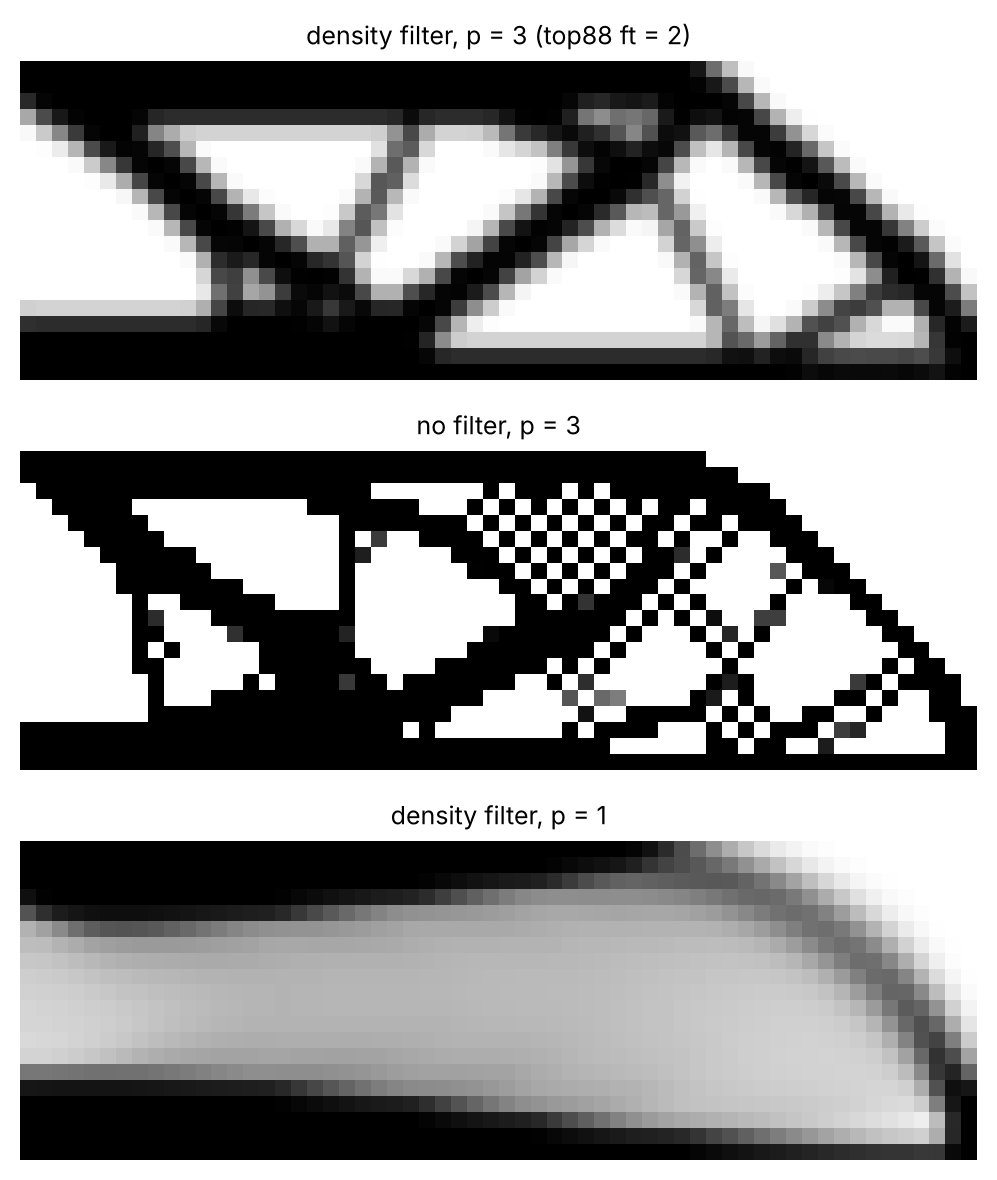

,case,compliance,iterations,grey_index,checkerboard_pct,compliance_p3_of_result
0,"density filter, p = 3 (top88 ft = 2)",218.801,126,0.269,0.357,218.801
1,"no filter, p = 3",203.211,63,0.012,11.508,203.211
2,"density filter, p = 1",164.674,34,0.576,0.000,425.296


In [2]:
tab, fields = verify.mbb_benchmark()
fig, axes = plt.subplots(3, 1, figsize=(6, 6))
for ax, (name, f) in zip(axes, fields.items()):
    ax.imshow(1 - f, cmap="gray", origin="lower", vmin=0, vmax=1); ax.set_title(name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
tab.round(3)

## 2. Plate model checks
- The ACM plate element against Navier (a simply supported square plate under uniform load).
- The quarter-symmetry model against the whole plate.
- Adjoint gradients against finite differences.

In [3]:
spec = PlateSpec(m_batt=9.48)   # heaviest pack set in the M1 design set (E, 4xB6S-16K)
pd.concat([verify.plate_element(), verify.symmetry_check(spec, 20), verify.gradient_check(spec)])

,check,mesh,value,reference,rel_error_pct
0,"ACM element: SS square plate, w_max D / (q a^4)",8 x 8,4.129333e-03,0.004062,1.648878e+00
1,"ACM element: SS square plate, w_max D / (q a^4)",16 x 16,4.079104e-03,0.004062,4.124283e-01
2,"ACM element: SS square plate, w_max D / (q a^4)",32 x 32,4.066541e-03,0.004062,1.031714e-01
3,"ACM element: SS square plate, w_max D / (q a^4)",64 x 64,4.063400e-03,0.004062,2.584310e-02
0,"symmetry: solid plate compliance, 4 x quarter ...",20^2 quarter / 40^2 whole,6.471313e+01,64.713126,-6.163847e-10
0,adjoint dc/dx vs central difference (6 random ...,"8^2 quarter, step 0.0001",7.682167e-07,0.000000,7.682167e-05
1,adjoint dc/dx vs central difference (6 random ...,"8^2 quarter, step 1e-06",3.012581e-05,0.000000,3.012581e-03


## 3. Boundary conditions and the solid plate
- Supports: w = 0 on 10 × 10 mm corner patches (arm clamps), with rotations free.
- Load: F = 2 g × m_batt, pointing down, over the central 40 × 40 mm.
- Quarter model: 40 × 40 elements of 2 mm.

F = 186.0 N, solid-plate compliance 57.16 N mm, solid mass 247.4 g


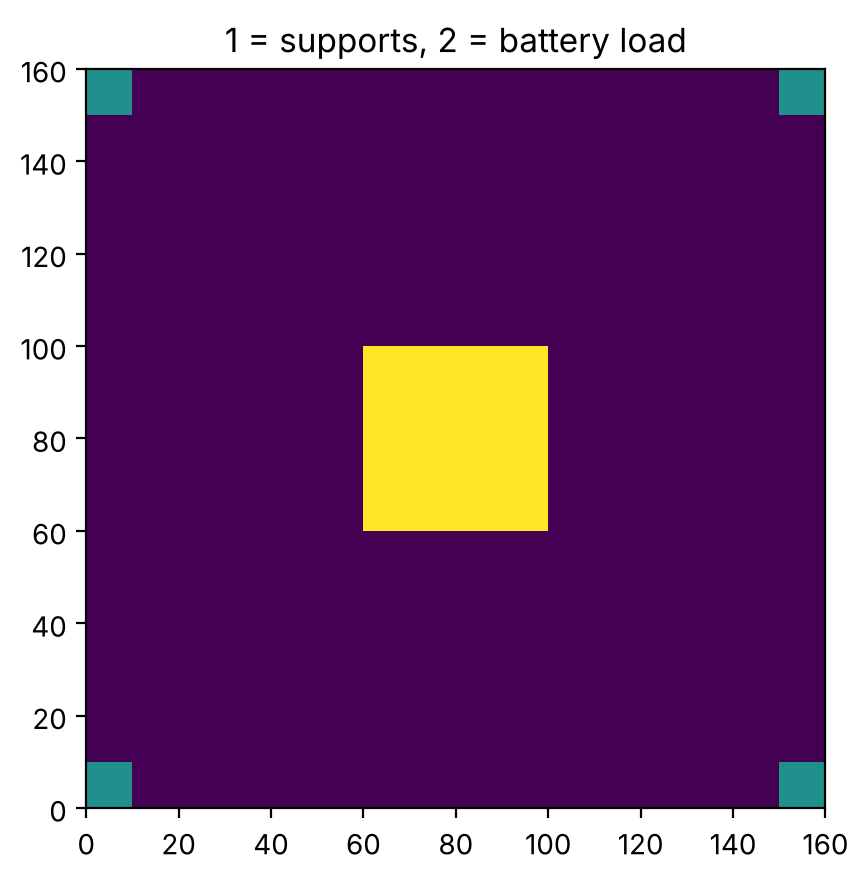

In [4]:
p, k = build(spec, 40)
c_solid = k * p.compliance(np.ones(p.grid.nel))
print(f"F = {spec.F:.1f} N, solid-plate compliance {c_solid:.2f} N mm, solid mass {1000*spec.mass(1):.1f} g")
img = np.zeros((40, 40)); img[p.solid.reshape(40, 40)] = 1; img[p.inload.reshape(40, 40)] = 2
plt.imshow(quarter_to_full(img), origin="lower", extent=(0, 160, 0, 160)); plt.title("1 = supports, 2 = battery load"); plt.show()

## 4. One volume fraction, end to end
Steps: SIMP → threshold → 6 mm outline → analyse the cut part on a 1 mm mesh.

*Prediction:* an X-shaped plate, with arms running from the corners to a central pad.

SIMP: c/c_solid 2.86, grey index 0.15, 71 iterations
cut part: vf 0.332, mass 108.7 g, c/c_solid 2.31, min member 6.75 mm, 6 mm check removes 0.0 mm2


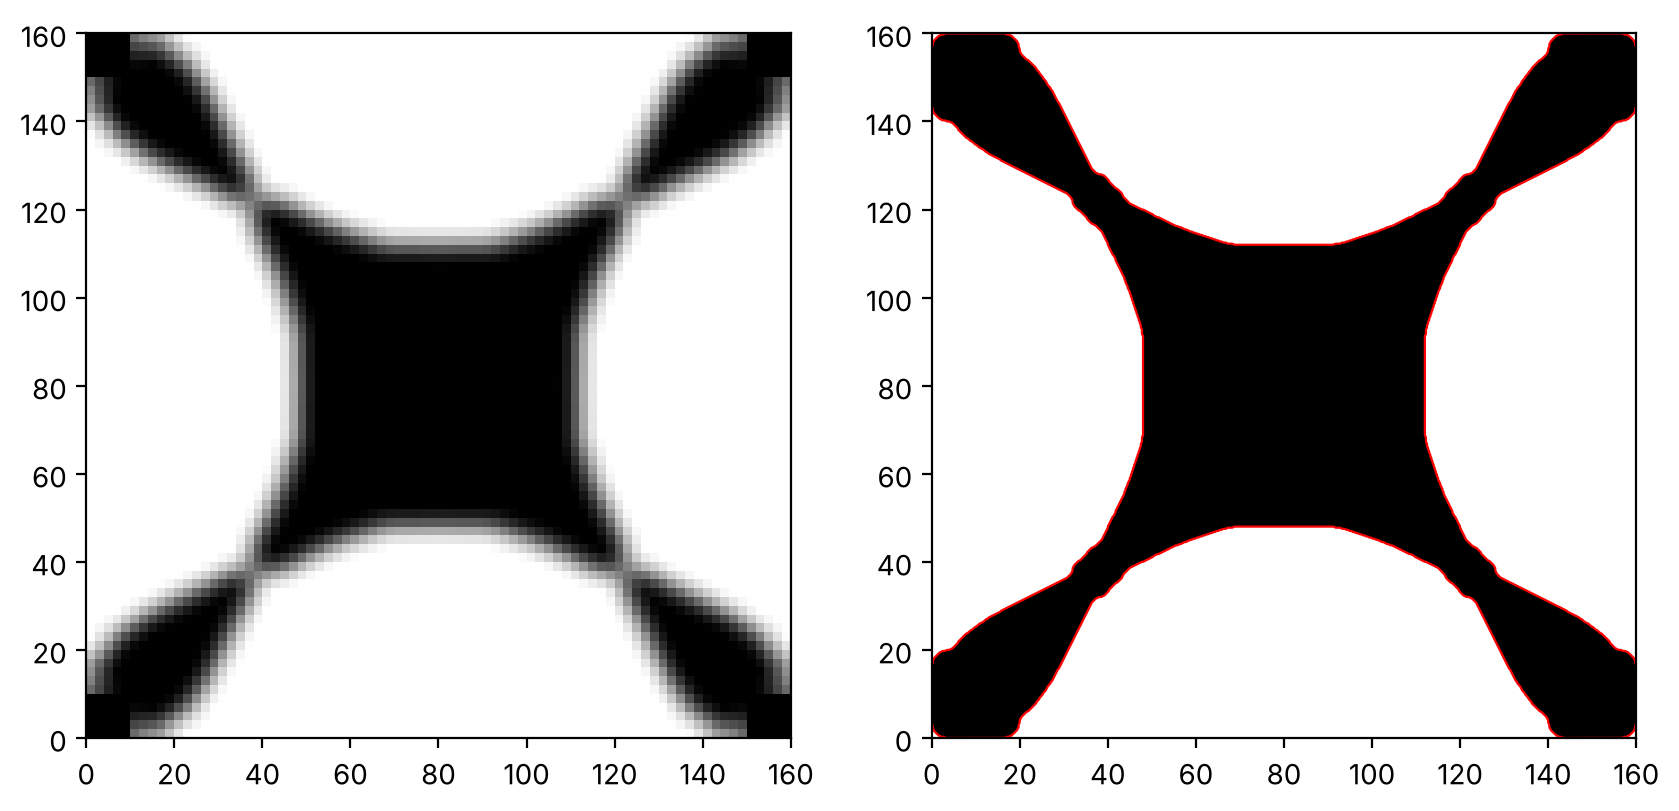

In [5]:
vf = 0.32
r = optimise(p, vf, penal=3.0, rmin=6.0 / p.grid.h)
rho = quarter_to_full(r["rho"].reshape(40, 40))
o = make_outline(rho, vf)
a = analyse_cut(spec, o["binary"])
print(f"SIMP: c/c_solid {k*r['c']/c_solid:.2f}, grey index {grey_index(rho):.2f}, {r['iters']} iterations")
print(f"cut part: vf {o['area_fraction']:.3f}, mass {1000*spec.mass(o['area_fraction']):.1f} g, c/c_solid {a['ratio']:.2f}, "
      f"min member {o['min_width_mm']:.2f} mm, 6 mm check removes {o['removed_by_check_mm2']:.1f} mm2")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5))
a1.imshow(1 - rho, cmap="gray", origin="lower", extent=(0, 160, 0, 160))
a2.imshow(~o["binary"], cmap="gray", origin="lower", extent=(0, 160, 0, 160))
for ln in o["contours"]: a2.plot(ln[:, 0], ln[:, 1], "r-", lw=0.8)
plt.show()

## 5. Sweep and choice (output from `run_all.py`)
`run.py` sweeps vf from 0.20 to 0.50 in steps of 0.05. It then refines in steps of 0.01 near the limit and keeps the lightest cut part with compliance ≤ 2.4 × solid (the 2.5 limit minus a mesh margin). To regenerate, run `python run_all.py --only m1 m2`.

In [6]:
sweep = pd.read_csv(root / "results/m2_sweep.csv")
display(sweep[["vf", "mass_nominal_kg", "ratio_simp", "vf_cut", "mass_cut_kg", "ratio_cut", "min_member_mm"]].round(3))
pd.read_csv(root / "results/m2_design.csv", index_col=0)

,vf,mass_nominal_kg,ratio_simp,vf_cut,mass_cut_kg,ratio_cut,min_member_mm
0,0.20,0.081,6.004,0.218,0.085,5.195,6.00
1,0.25,0.092,4.138,0.274,0.097,3.022,6.00
2,0.30,0.102,3.142,0.320,0.106,2.470,6.00
3,0.31,0.104,2.993,0.339,0.110,2.307,6.00
4,0.32,0.106,2.863,0.332,0.109,2.314,6.75
5,0.33,0.108,2.729,0.343,0.111,2.233,6.00
6,0.34,0.110,2.618,0.352,0.113,2.169,6.00
7,0.35,0.113,2.519,0.362,0.115,2.100,6.00
8,0.40,0.123,2.094,0.406,0.124,1.829,7.25
9,0.45,0.133,1.807,0.460,0.135,1.613,6.00


,value
mesh,coarse
element_mm,2.0
filter_radius_mm,6.0
penal,3.0
battery_kg,9.48
load_N,185.9976
vf_simp,0.32
vf_cut,0.33150390625
plate_mass_kg,0.10874065
plate_mass_solid_kg,0.24736000000000002


![compliance vs mass](../figures/m2_compliance_vs_mass.png)

![outline](../figures/m2_outline.png)

## 6. Plate mass back into M1 (re-run once, FM0 and surrogate FM)
*Observation:* the continuous optima fall by more than the 141 g saved on the plate (the mass snowball). Write the factor here.

In [7]:
fb = pd.read_csv(root / "results/m2_m1_feedback.csv")
fb[["path", "design", "m_cont_before", "m_cont_after", "dm_cont_g", "m_snap_before", "m_snap_after", "dm_snap_g", "parts_before", "parts_after"]].round(3)

,path,design,m_cont_before,m_cont_after,dm_cont_g,m_snap_before,m_snap_after,dm_snap_g,parts_before,parts_after
0,FM0 = 0.65,A light,6.617,6.388,-228.87,7.220,6.773,-446.81,"1xB6S-12K, M45, CF40x1.5, 29 in","1xB6S-12K, M45, CF40x1.0, 26 in"
1,FM0 = 0.65,B all-but-one,7.989,7.708,-281.53,8.395,8.215,-180.05,"1xB6S-22K, M45, CF40x1.0, 26 in","1xB6S-22K, M45, CF40x1.0, 25 in"
2,FM0 = 0.65,C cover-all,9.594,9.259,-334.40,10.400,10.209,-191.60,"4xB6S-8K, M60, CF40x1.5, 29 in","4xB6S-8K, M60, CF40x1.5, 28 in"
3,FM0 = 0.65,D 4-hub,10.275,9.916,-359.11,11.020,10.829,-191.60,"3xB6S-12K, M60, CF40x1.5, 29 in","3xB6S-12K, M60, CF40x1.5, 28 in"
4,FM0 = 0.65,E 3-hub,13.711,13.176,-535.50,15.715,15.515,-200.13,"4xB6S-16K, M80, CF40x2.0, 30 in","4xB6S-16K, M80, CF40x2.0, 29 in"
5,surrogate FM (cubic RBF),A light,6.890,6.658,-231.95,7.251,7.081,-170.26,"2xB6S-8K, M45, CF35x1.0, 20 in","2xB6S-8K, M45, CF35x1.0, 19 in"
6,surrogate FM (cubic RBF),B all-but-one,8.525,8.273,-251.94,8.675,8.495,-180.05,"3xB6S-8K, M45, CF40x1.0, 26 in","3xB6S-8K, M45, CF40x1.0, 25 in"
7,surrogate FM (cubic RBF),C cover-all,10.334,10.022,-311.73,10.921,10.732,-188.70,"3xB6S-12K, M60, CF40x1.5, 27 in","3xB6S-12K, M60, CF40x1.5, 26 in"
8,surrogate FM (cubic RBF),D 4-hub,11.128,10.793,-335.13,11.782,11.641,-141.26,"2xB6S-22K, M60, CF40x1.0, 23 in","2xB6S-22K, M60, CF40x1.0, 23 in"
9,surrogate FM (cubic RBF),E 3-hub,14.479,14.132,-347.02,15.381,15.192,-188.70,"4xB6S-16K, M80, CF40x1.5, 27 in","4xB6S-16K, M80, CF40x1.5, 26 in"
